# 02 — Project-learned effect, directional ranking, and decile diagnostics

This notebook consolidates the analyses developed after the published benchmark metrics. It uses the
**frozen, already-audited BH-corrected WGS reference**; it does not rediscover labels, select studies,
or rerun multiple-testing choices. Every panel covers all 10 eligible biological contrasts and compares
PICRUSt2 with the cached basic-MLP adaptation.

WGS-derived labels are target-informed, cohort-conditional, post-hoc diagnostics and are not deployable
prediction targets.

## Attribution boundary

The effect-size relationship, directional ROC/precision-recall summaries, AUROC/average precision,
and prediction-ranked decile composition in this notebook are **project-developed extensions**. They
are not attributed to the PICRUSt, PICRUSt2, Tax4Fun2, Sun, or Matchado papers. The BH set-recovery
section uses published differential-KO set-recovery precedent, but its WGS-only family, BH correction,
and zero-fill policy are repository-specific. Complete citations and ownership notes are in
`docs/REFERENCES.md`.

### Exact project modification

Matchado et al. used unadjusted *p* < 0.05 for their differential-KO recovery metric. This notebook
does **not** reuse that significance rule. It uses the following project definition:

1. Within each study, define one KO family from KOs detected in at least 5% of labeled WGS samples.
2. Run one two-sided rank-sum test per KO and apply Benjamini-Hochberg across the complete WGS family.
3. Define the WGS reference-positive set with BH *q* < 0.05.
4. Normalize each prediction over its complete source profile, align it to the same WGS family, and
   score absent prediction KOs as zero; do not apply a prediction-side prevalence filter.
5. Test and BH-adjust each prediction over that same family, then compute precision, recall, and F1
   against the fixed WGS positives.

**Why:** thousands of KOs are tested simultaneously, so BH limits the expected false-discovery
proportion among selected KOs. Fixing the family from WGS prevents a method from changing the target
simply by omitting KOs. These BH results are a project extension and must not be reported as Matchado's
original raw-*p* metric.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA = ROOT / "data"
STUDIES = DATA / "studies"
REFERENCE = DATA / "reference"
ANALYSIS = REFERENCE
FIGREF = REFERENCE
CONTRACT = REFERENCE
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from picrust_benchmark_metrics import (
    plot_directional_metric_summary,
    plot_directional_roc_grid,
    plot_ko_coverage,
    plot_matchado_randomization_dumbbells,
    plot_method_differences,
    plot_metric_row_grid,
    plot_profile_study_panels,
    plot_signed_decile_grid,
    plot_stratum_mean_ranges,
    plot_sun_observed_controls,
)
sns.set_theme(style="whitegrid", context="notebook")
METHODS = ["PICRUSt2", "PICRUSt2 + adaptation"]
COLORS = {"PICRUSt2": "#4C78A8", "PICRUSt2 + adaptation": "#E45756"}
COLORS["Tax4Fun2"] = "#F2A900"
assert STUDIES.is_dir() and REFERENCE.is_dir(), "Run from a complete repository checkout"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

from picrust_benchmark_metrics import directional_ranking_curves, decile_outcome_composition

## Frozen biological contrasts and per-KO surface

The study/label selection and BH corrections were completed in the accepted source run. Topsoil is not
included because it had zero BH-selected WGS KOs; the other 16 strata have no accepted binary phenotype.

In [2]:
cohort = pd.read_csv(ANALYSIS / "effect_cohort.tsv", sep="\t")
selection = pd.read_csv(ANALYSIS / "effect_selection_fixed.tsv", sep="\t")
assignments = pd.read_csv(ANALYSIS / "quantile_per_ko_assignments.tsv.gz", sep="\t")
assignments = assignments[assignments.prediction_method.isin(METHODS)].copy()
effect_ref = pd.read_csv(ANALYSIS / "effect_long.tsv", sep="\t")
effect_ref = effect_ref[effect_ref.method_label.isin(METHODS)].copy()
class_ref = pd.read_csv(ANALYSIS / "classification_summary.tsv", sep="\t")
class_ref = class_ref[class_ref.prediction_method.isin(METHODS)].copy()
decile_ref = pd.read_csv(ANALYSIS / "quantile_composition_by_bin.tsv", sep="\t")
decile_ref = decile_ref[decile_ref.prediction_method.isin(METHODS)].copy()
decile_baselines = pd.read_csv(ANALYSIS / "quantile_study_baselines.tsv", sep="\t")
inputs_02 = [
    ANALYSIS / "effect_cohort.tsv", ANALYSIS / "effect_selection_fixed.tsv",
    ANALYSIS / "quantile_per_ko_assignments.tsv.gz", ANALYSIS / "effect_long.tsv",
    ANALYSIS / "classification_summary.tsv", ANALYSIS / "quantile_composition_by_bin.tsv",
    ANALYSIS / "quantile_study_baselines.tsv",
    FIGREF / "pr_roc_metric_summary.tsv",
]
provenance_02 = pd.DataFrame({"path": [p.relative_to(ROOT).as_posix() for p in inputs_02], "bytes": [p.stat().st_size for p in inputs_02],
                              "sha256": [sha256(p) for p in inputs_02]})
assert cohort.dataset.nunique() == selection.dataset.nunique() == assignments.dataset.nunique() == 10
assert assignments.groupby(["dataset", "prediction_method"]).ngroups == 20
assert int((assignments.wgs_bh_qvalue == 0.05).sum()) == 0
threshold_contract = pd.DataFrame([
    {"analysis": "effect correlation", "WGS target rule": "BH q < 0.05", "prediction significance used": False,
     "status": "project extension"},
    {"analysis": "directional ROC/PR", "WGS target rule": "BH q <= 0.05 plus effect sign", "prediction significance used": False,
     "status": "project extension"},
    {"analysis": "decile composition", "WGS target rule": "BH q <= 0.05 plus effect sign", "prediction significance used": False,
     "status": "project extension"},
    {"analysis": "BH set recovery", "WGS target rule": "BH q < 0.05", "prediction significance used": True,
     "status": "project extension; not Matchado raw-p"},
])
display(cohort[["dataset", "group_a", "group_b", "n_group_a", "n_group_b", "n_eligible_kos"]])
display(threshold_contract)
display(provenance_02)

,dataset,group_a,group_b,n_group_a,n_group_b,n_eligible_kos
0,blueberry,Bulk,Rhizosphere,8,7,4319
1,cameroon,Entamoeba positive,Entamoeba negative,19,36,5396
2,hmp,Gastrointestinal_tract,Oral,66,63,4799
3,indian,Location 1,Location 2,51,55,4636
4,primate,New World,Old World,29,29,4205
5,matchado,CRC,CTR,41,50,5229
6,brooks_forward,BV,nonBV,4,26,1184
7,sun_human_kw,rural,urban,20,20,4328
8,activated_sludge,disturbed,stable,16,17,5829
9,han_river,upstream,downstream,30,15,8393


,analysis,WGS target rule,prediction significance used,status
0,effect correlation,BH q < 0.05,False,project extension
1,directional ROC/PR,BH q <= 0.05 plus effect sign,False,project extension
2,decile composition,BH q <= 0.05 plus effect sign,False,project extension
3,BH set recovery,BH q < 0.05,True,project extension; not Matchado raw-p


,path,bytes,sha256
0,data/reference/effect_cohort.tsv,1910,6ecba83f102af5fe8495454d27cda18172b1013e61dc4b...
1,data/reference/effect_selection_fixed.tsv,2038,a0e7261aa50f445eba4d2f5e8d702a5451d6267706bbfb...
2,data/reference/quantile_per_ko_assignments.tsv.gz,5599022,1959a29ed9d918dd32fffe7cc0c83fb6522df62d49f704...
3,data/reference/effect_long.tsv,30983,0ef4309074d3e4695df626ee80a9373e056b991eff466e...
4,data/reference/classification_summary.tsv,23415,37de246363b435fdd8e41dde5cd273e92de6b258ce7938...
5,data/reference/quantile_composition_by_bin.tsv,212954,b340ed079f5ec79287f22b3a81b7ca07035ed0e39b8c07...
6,data/reference/quantile_study_baselines.tsv,2011,ae8e2fb15542da622803c8f8cce15294340d32edc80421...
7,data/reference/pr_roc_metric_summary.tsv,23120,e8d36e6fa96e219b0ff3e4b4b355c248a944822bd33c53...


## WGS-versus-predicted effect-size relation

Rank-biserial effects use `2U/(nA*nB)-1`. Spearman and Pearson correlations are recomputed directly
from every eligible per-KO row and checked against the accepted `effect_long.tsv` values.

In [3]:
effect_rows = []
for (dataset, method), block in assignments.groupby(["dataset", "prediction_method"], sort=False):
    selected = block[block.wgs_bh_qvalue < 0.05]
    effect_rows += [
        {"dataset": dataset, "method_label": method, "metric": "spearman",
         "effect_correlation_new": selected.wgs_rank_biserial_effect.corr(selected.prediction_effect, method="spearman")},
        {"dataset": dataset, "method_label": method, "metric": "pearson",
         "effect_correlation_new": selected.wgs_rank_biserial_effect.corr(selected.prediction_effect, method="pearson")},
    ]
effect_new = pd.DataFrame(effect_rows)
effect_cmp = effect_new.merge(effect_ref[["dataset", "method_label", "metric", "effect_correlation"]],
                              on=["dataset", "method_label", "metric"], validate="one_to_one")
effect_cmp["absolute_error"] = (effect_cmp.effect_correlation_new - effect_cmp.effect_correlation).abs()
assert effect_cmp.absolute_error.max() <= 1e-12
print("Maximum effect-correlation absolute error:", f"{effect_cmp.absolute_error.max():.3g}")
pivot = effect_cmp[effect_cmp.metric.eq("spearman")].pivot(index="dataset", columns="method_label", values="effect_correlation_new")
display(pivot)

Maximum effect-correlation absolute error: 7.77e-16


method_label,PICRUSt2,PICRUSt2 + adaptation
dataset,,
activated_sludge,0.470089,0.391763
blueberry,0.119163,0.220151
brooks_forward,0.510611,0.455170
cameroon,0.546655,0.550287
han_river,0.467738,0.397531
hmp,0.674540,0.644365
indian,0.664517,0.619910
matchado,0.780901,0.719998
primate,0.328980,0.314121


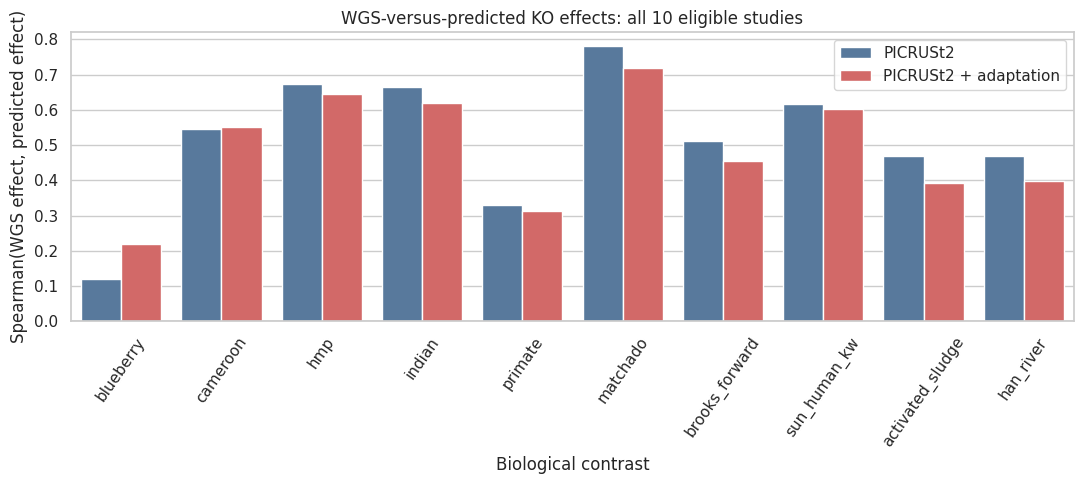

In [4]:
# Plot 1: all-study effect-correlation comparison.
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=effect_cmp[effect_cmp.metric.eq("spearman")], x="dataset", y="effect_correlation_new",
            hue="method_label", hue_order=METHODS, palette=COLORS, ax=ax)
ax.axhline(0, color="black", lw=.8)
ax.set(xlabel="Biological contrast", ylabel="Spearman(WGS effect, predicted effect)",
       title="WGS-versus-predicted KO effects: all 10 eligible studies")
ax.tick_params(axis="x", rotation=55)
ax.legend(title="")
fig.tight_layout()

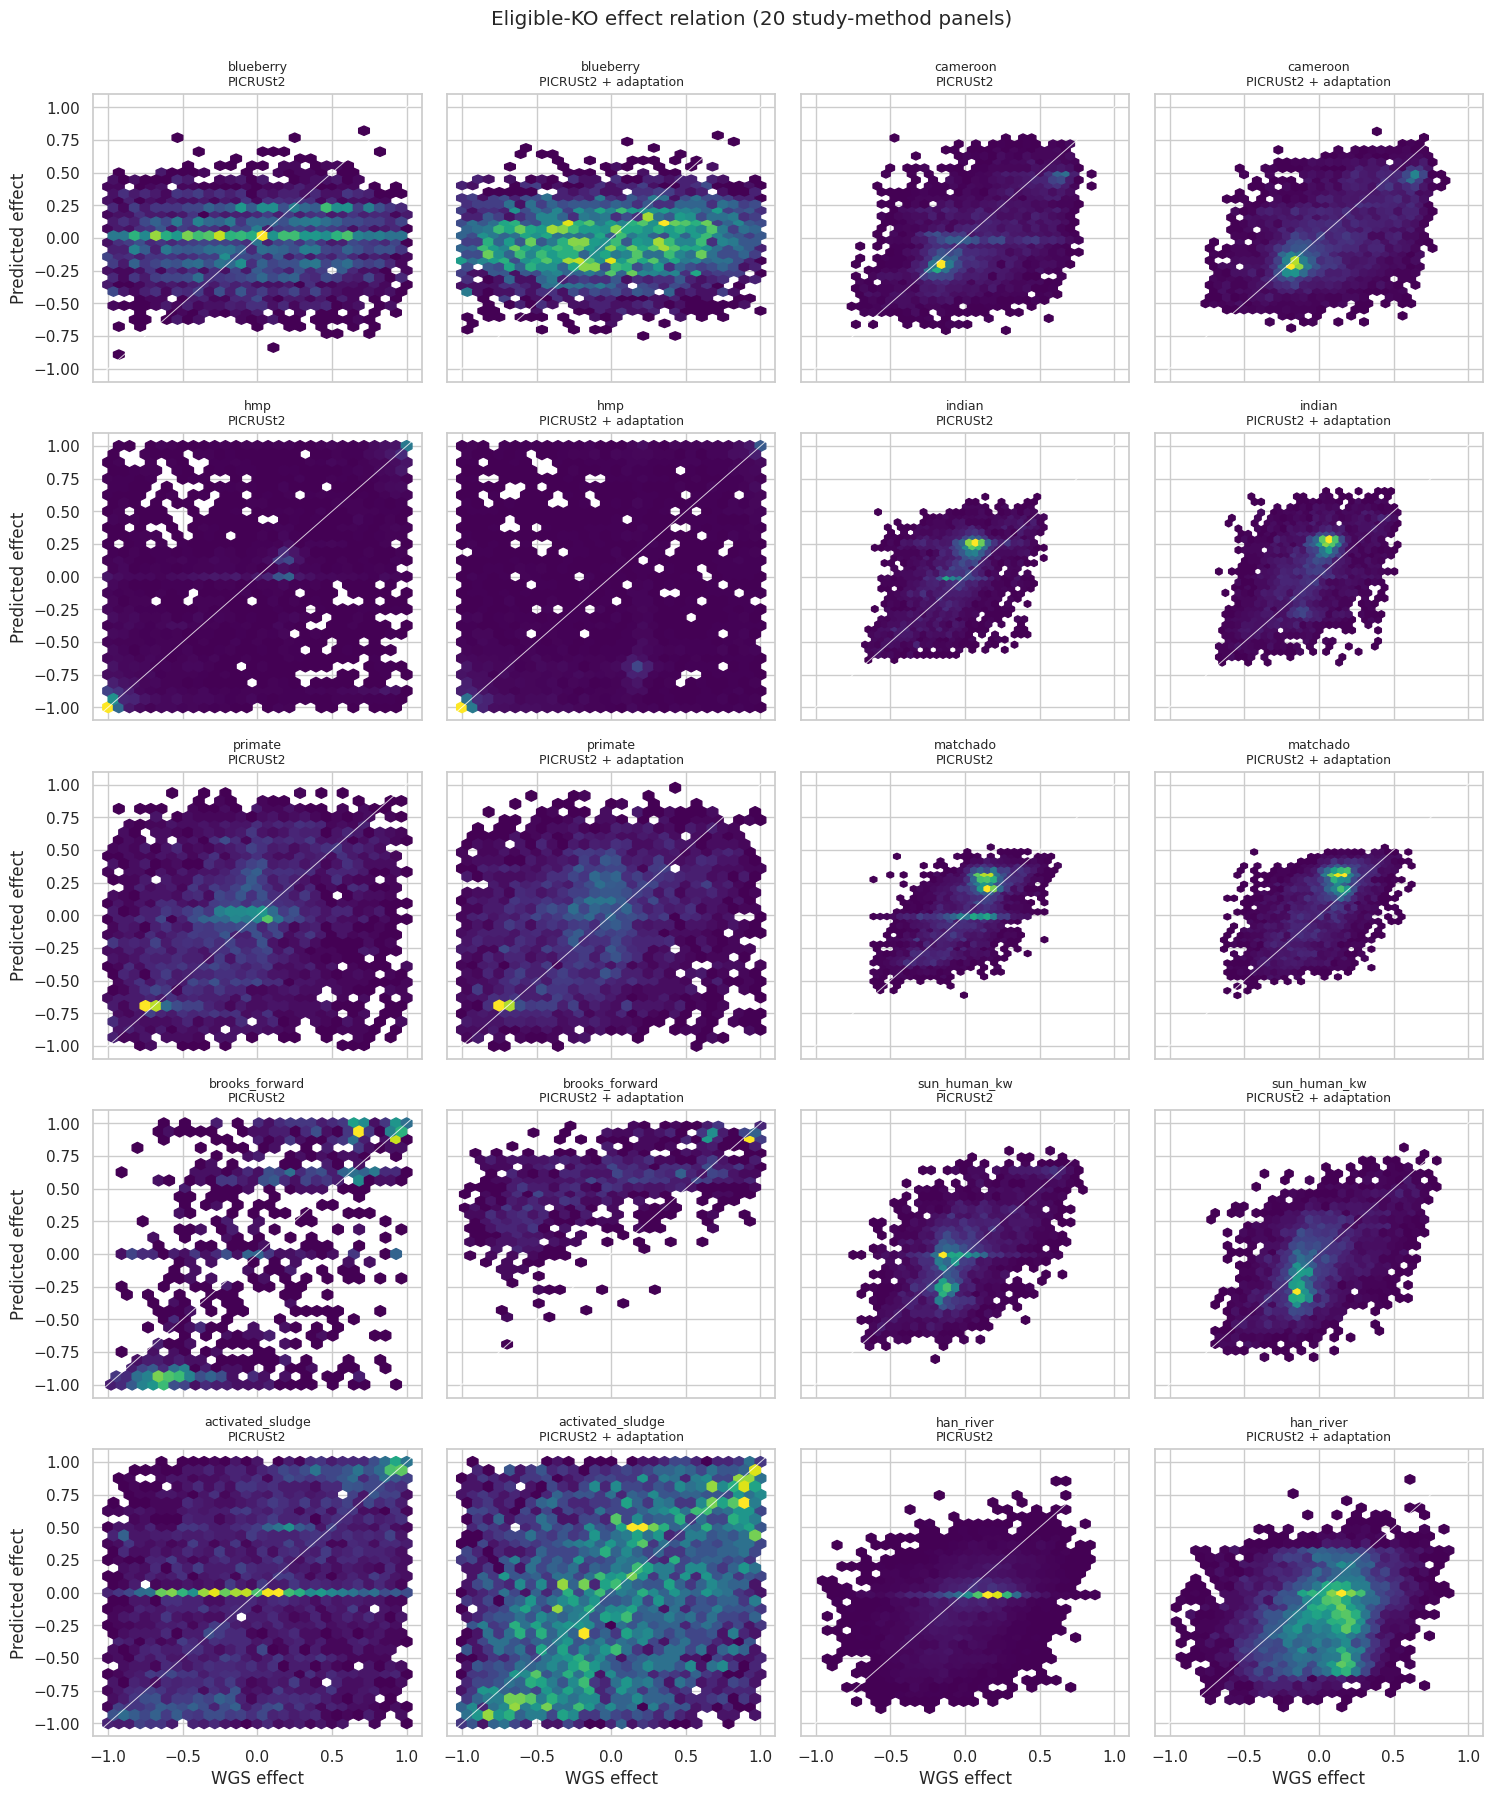

In [5]:
# Plot 2: per-KO effect scatter for every study and both methods.
fig, axes = plt.subplots(5, 4, figsize=(15, 18), sharex=True, sharey=True)
for ax, ((dataset, method), block) in zip(axes.flat, assignments.groupby(["dataset", "prediction_method"], sort=False)):
    ax.hexbin(block.wgs_rank_biserial_effect, block.prediction_effect, gridsize=28, mincnt=1, cmap="viridis")
    ax.axline((0, 0), slope=1, color="white", lw=.7, alpha=.8)
    ax.set_title(f"{dataset}\n{method}", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("WGS effect")
for ax in axes[:, 0]: ax.set_ylabel("Predicted effect")
fig.suptitle("Eligible-KO effect relation (20 study-method panels)", y=.998)
fig.tight_layout()

## Directional PR and ROC

Positive targets are WGS BH q ≤ 0.05 with positive effect; negative targets use q ≤ 0.05 with negative
effect and score `−prediction_effect`. AP is sklearn average precision—not trapezoidal PR area.
Every summary is independently recomputed with the clean library and compared to the completed figure
source table.

In [6]:
curve_ref = pd.read_csv(FIGREF / "pr_roc_metric_summary.tsv", sep="\t")
curve_ref = curve_ref[curve_ref.prediction_method.isin(METHODS)].copy()
curve_rows, pr_tables, roc_tables = [], [], []
for (dataset, method), block in assignments.groupby(["dataset", "prediction_method"], sort=False):
    pr, roc, summary = directional_ranking_curves(block.wgs_bh_qvalue, block.wgs_rank_biserial_effect, block.prediction_effect)
    summary.insert(0, "prediction_method", method); summary.insert(0, "dataset", dataset)
    pr.insert(0, "prediction_method", method); pr.insert(0, "dataset", dataset)
    roc.insert(0, "prediction_method", method); roc.insert(0, "dataset", dataset)
    curve_rows.append(summary); pr_tables.append(pr); roc_tables.append(roc)
curve_new = pd.concat(curve_rows, ignore_index=True)
pr_values = pd.concat(pr_tables, ignore_index=True); roc_values = pd.concat(roc_tables, ignore_index=True)
curve_cmp = curve_new.merge(curve_ref[["dataset", "prediction_method", "direction", "ap_sklearn", "roc_auc_sklearn"]],
                            on=["dataset", "prediction_method", "direction"], validate="one_to_one")
curve_cmp["ap_error"] = (curve_cmp.ap - curve_cmp.ap_sklearn).abs()
curve_cmp["roc_error"] = (curve_cmp.roc_auc - curve_cmp.roc_auc_sklearn).abs()
assert curve_cmp[["ap_error", "roc_error"]].max().max() <= 1e-12
print("Maximum AP/ROC-AUC absolute error:", f"{curve_cmp[['ap_error','roc_error']].max().max():.3g}")

Maximum AP/ROC-AUC absolute error: 1.11e-16


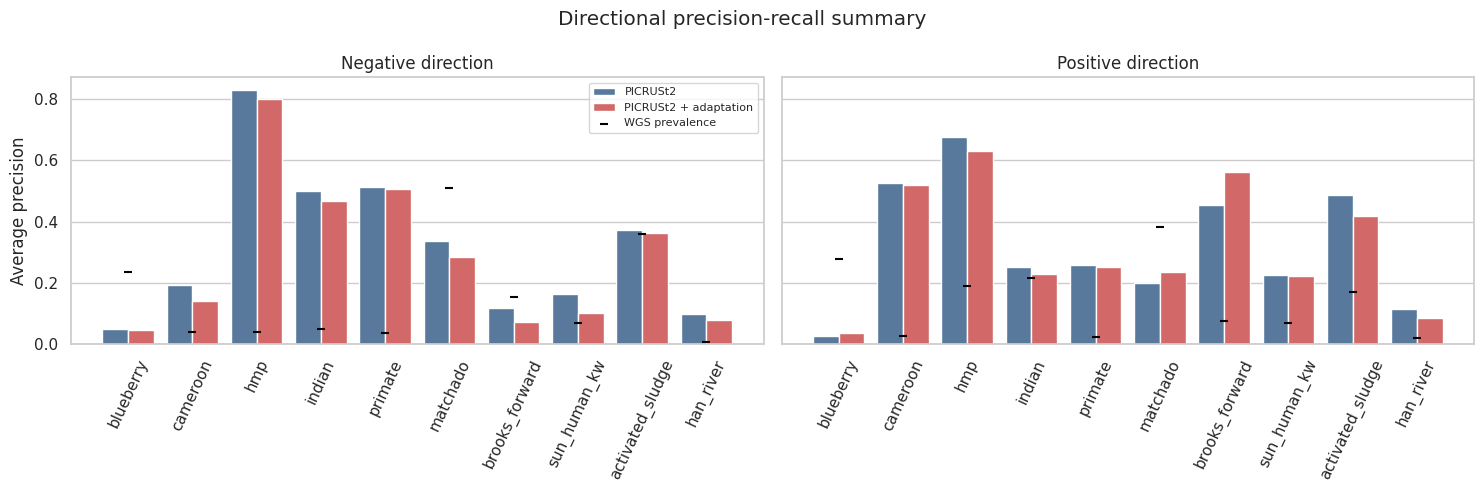

In [7]:
# Plot 3: directional average precision across all studies.
fig, axes = plot_directional_metric_summary(curve_new, "ap", METHODS, colors=COLORS)

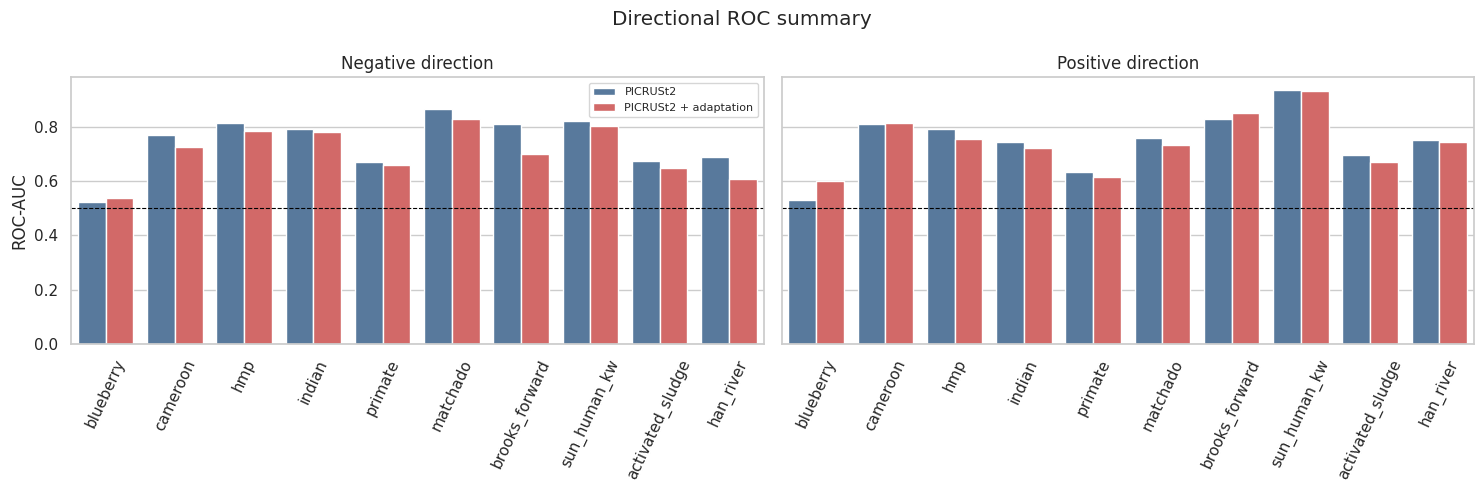

In [8]:
# Plot 4: directional ROC-AUC across all studies.
fig, axes = plot_directional_metric_summary(curve_new, "roc_auc", METHODS, colors=COLORS)

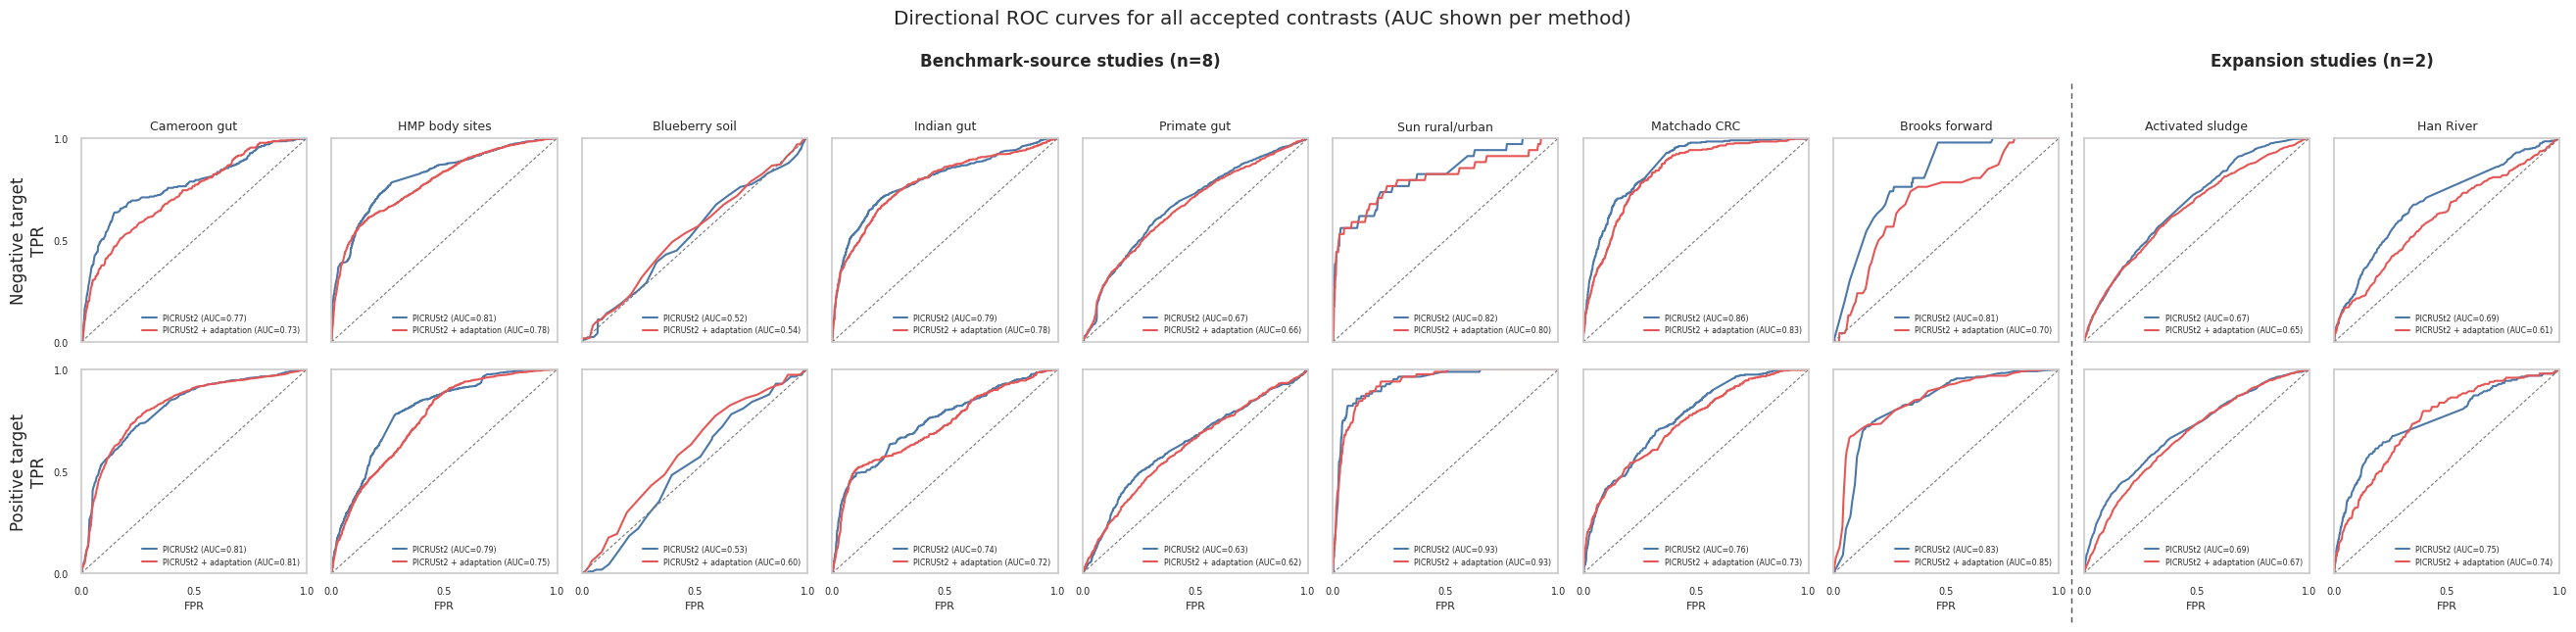

In [9]:
# Plot 5: full directional ROC curves, with the independently recomputed AUC in every panel.
from matplotlib.lines import Line2D

STUDY_ORDER = ["cameroon", "hmp", "blueberry", "indian", "primate", "sun_human_kw",
               "matchado", "brooks_forward", "activated_sludge", "han_river"]
display_names = (effect_ref[["dataset", "display_name"]].drop_duplicates("dataset")
                 .set_index("dataset").display_name.to_dict())
fig, axes = plot_directional_roc_grid(
    roc_values, curve_new, STUDY_ORDER, METHODS,
    display_names=display_names, colors=COLORS, benchmark_count=8
)

## Project BH recovery extension

**This is not Matchado's unadjusted p < 0.05 metric.** This project implementation combines the
differential-KO set-recovery precedent in Douglas et al. (2020) and Matchado et al. (2024) with a
WGS-only detectable family. WGS and each prediction are BH-adjusted separately over that same family;
positives require q < 0.05. The family is shared by both methods, and absent prediction KOs are scored
as zero. We chose BH to limit the expected false-discovery proportion across the thousands of
simultaneous KO tests. The plot uses the completed 400-permutation summary; it is not a new
randomization analysis in this notebook.

,dataset,prediction_method,precision,recall,f1,n_wgs_positive,n_prediction_positive_seed_mean
0,blueberry,PICRUSt2,NaN,0.000000,0.000000,340,0.0
2,blueberry,PICRUSt2 + adaptation,NaN,0.000000,0.000000,340,0.0
6,cameroon,PICRUSt2,0.571581,0.378895,0.455707,1412,936.0
8,cameroon,PICRUSt2 + adaptation,0.548428,0.308782,0.395106,1412,795.0
12,hmp,PICRUSt2,0.891079,0.779054,0.831310,4526,3957.0
14,hmp,PICRUSt2 + adaptation,0.764913,0.912285,0.832124,4526,5398.0
18,indian,PICRUSt2,0.406095,0.546756,0.466043,1048,1411.0
20,indian,PICRUSt2 + adaptation,0.298272,0.576336,0.393101,1048,2025.0
24,primate,PICRUSt2,0.558578,0.570341,0.564398,2232,2279.0
26,primate,PICRUSt2 + adaptation,0.544340,0.517025,0.530331,2232,2120.0


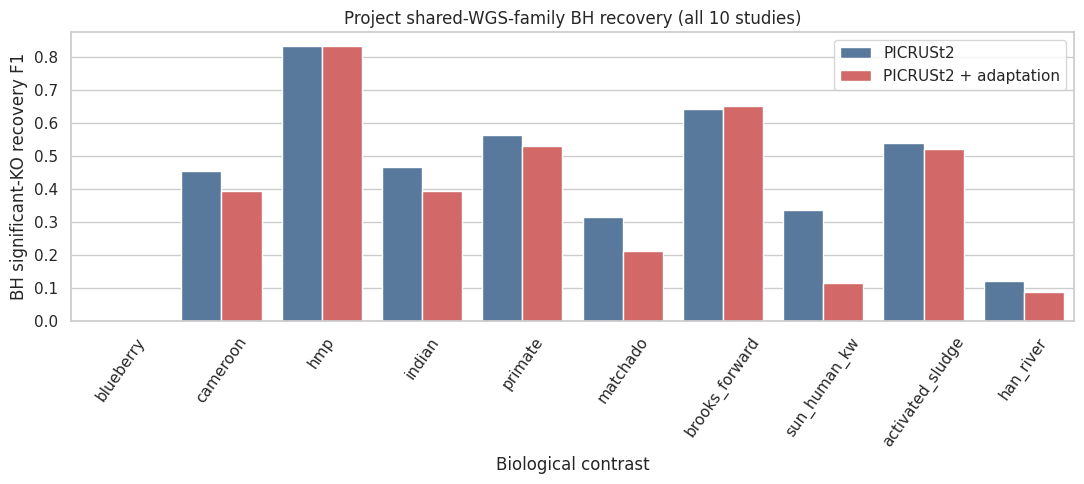

In [10]:
assert class_ref.groupby(["dataset", "prediction_method"]).ngroups == 20
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=class_ref, x="dataset", y="f1", hue="prediction_method", hue_order=METHODS, palette=COLORS, ax=ax)
ax.set(xlabel="Biological contrast", ylabel="BH significant-KO recovery F1",
       title="Project shared-WGS-family BH recovery (all 10 studies)")
ax.tick_params(axis="x", rotation=55)
ax.legend(title="")
fig.tight_layout()
display(class_ref[["dataset", "prediction_method", "precision", "recall", "f1", "n_wgs_positive", "n_prediction_positive_seed_mean"]])

## Decile outcome composition

KOs are sorted by predicted effect (ties broken lexically by KO ID), divided into ten equal-count rank
bins, and summarized by WGS class: significant negative, nonsignificant, or significant positive. This
provides the directional WGS outcome composition in each rank bin.

In [11]:
new_assignments, new_bins = [], []
for (dataset, method), block in assignments.groupby(["dataset", "prediction_method"], sort=False):
    assigned, bins = decile_outcome_composition(block.KO, block.prediction_effect,
                                                block.wgs_bh_qvalue, block.wgs_rank_biserial_effect)
    assigned.insert(0, "prediction_method", method); assigned.insert(0, "dataset", dataset)
    bins.insert(0, "prediction_method", method); bins.insert(0, "dataset", dataset)
    new_assignments.append(assigned); new_bins.append(bins)
decile_new = pd.concat(new_bins, ignore_index=True)
keys = ["dataset", "prediction_method", "bin"]
check_cols = ["n_kos", "p_sig_negative", "p_nonsignificant", "p_sig_positive", "p_any_significant", "balance_pos_minus_neg"]
decile_cmp = decile_new.merge(decile_ref[keys + check_cols], on=keys, suffixes=("_new", "_reference"), validate="one_to_one")
errors = []
for column in check_cols:
    errors.append(np.nanmax(np.abs(decile_cmp[f"{column}_new"].to_numpy(float) - decile_cmp[f"{column}_reference"].to_numpy(float))))
assert max(errors) <= 1e-12
print("Maximum decile-summary absolute error:", f"{max(errors):.3g}")

Maximum decile-summary absolute error: 1.11e-16


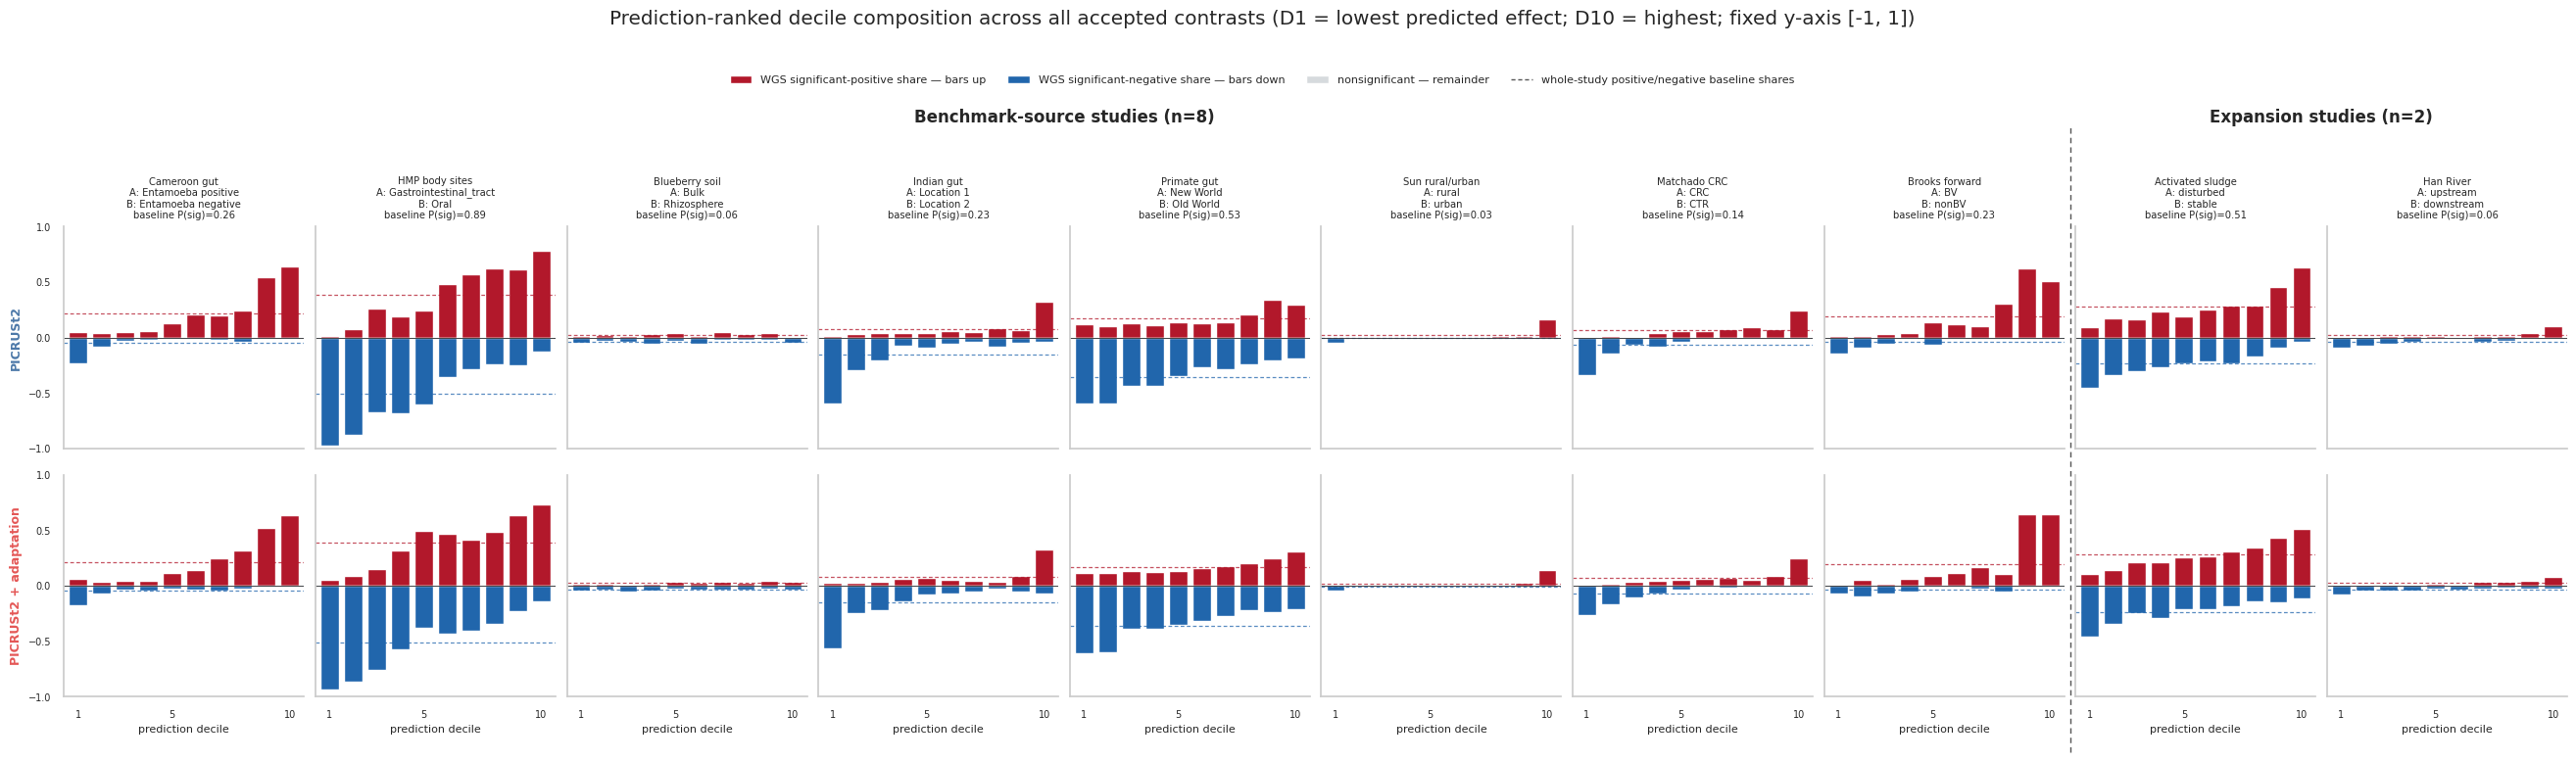

In [12]:
# Plot 6: signed decile composition, matching the consolidated all-study layout.

STUDY_ORDER = ["cameroon", "hmp", "blueberry", "indian", "primate", "sun_human_kw",
               "matchado", "brooks_forward", "activated_sludge", "han_river"]
display_names = (effect_ref[["dataset", "display_name"]].drop_duplicates("dataset")
                 .set_index("dataset").display_name.to_dict())
fig, axes = plot_signed_decile_grid(
    decile_new, decile_baselines, cohort, STUDY_ORDER, METHODS,
    display_names=display_names, colors=COLORS, benchmark_count=8
)

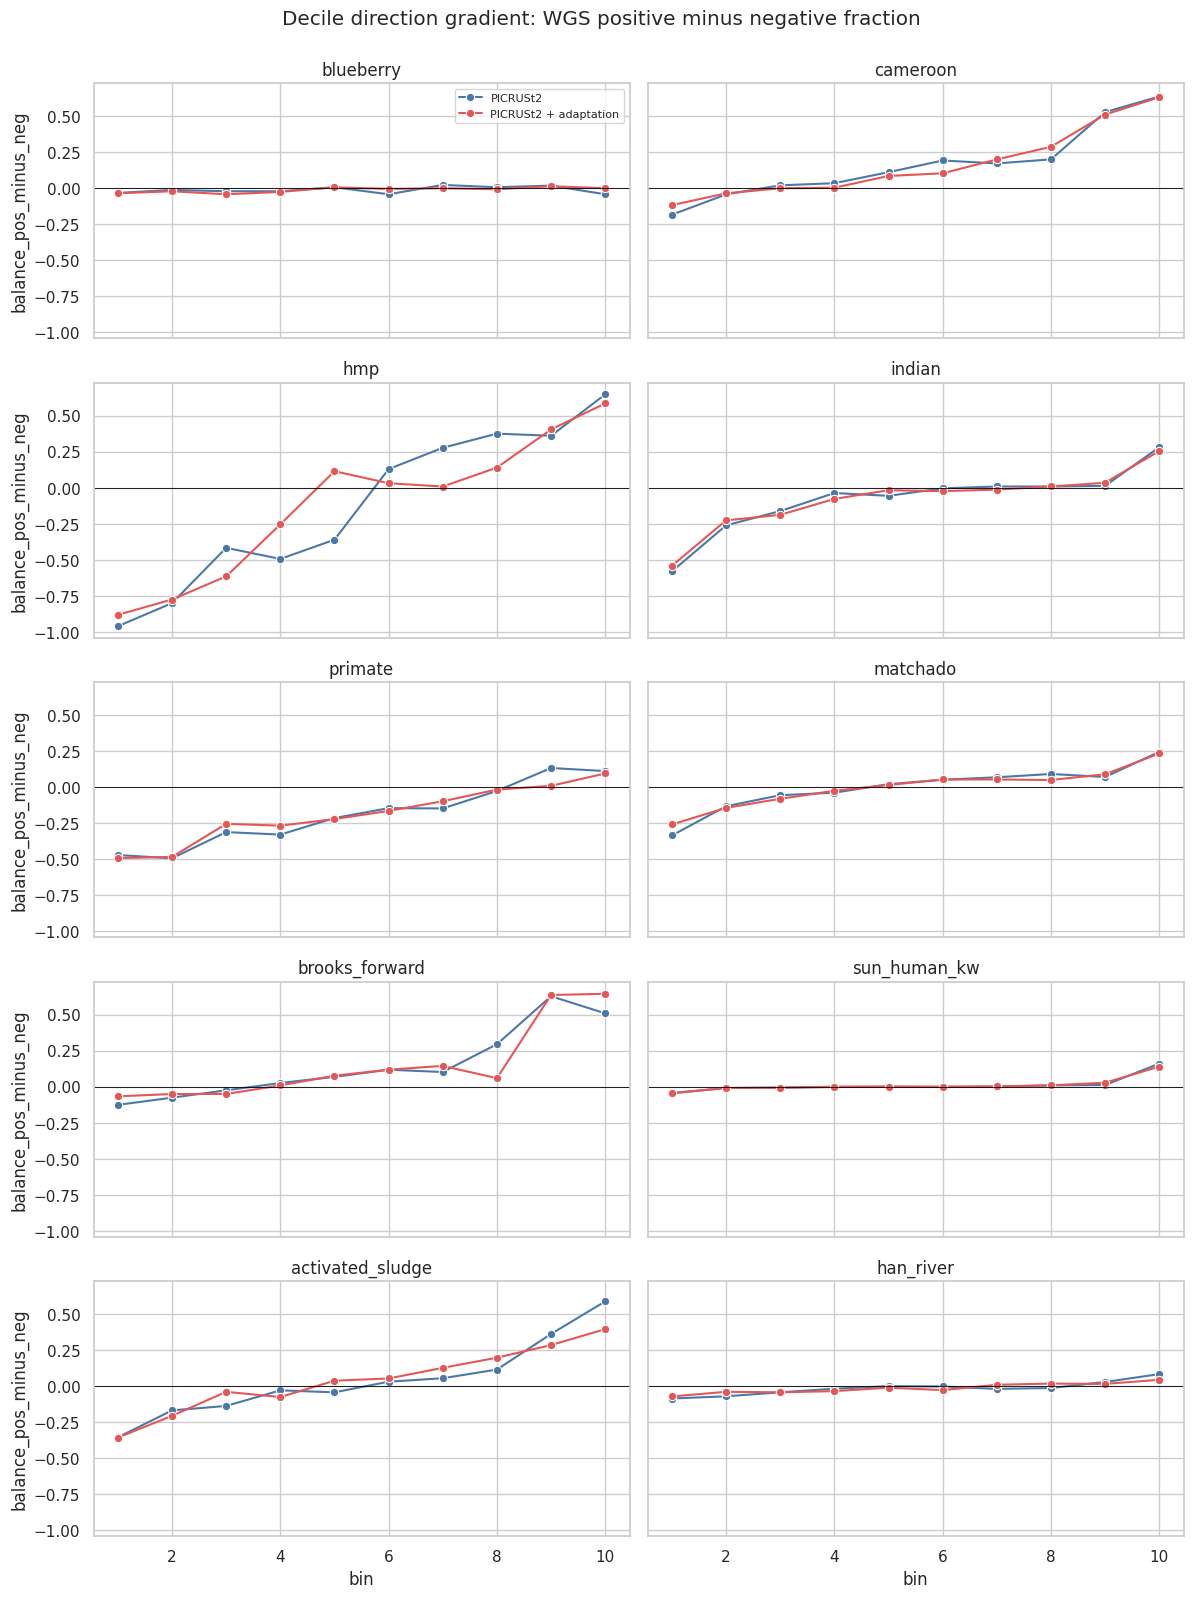

In [13]:
# Plot 7: compact directional gradient (positive minus negative outcome fraction).
fig, axes = plt.subplots(5, 2, figsize=(12, 16), sharex=True, sharey=True)
for ax, (dataset, block) in zip(axes.flat, decile_new.groupby("dataset", sort=False)):
    sns.lineplot(data=block, x="bin", y="balance_pos_minus_neg", hue="prediction_method",
                 hue_order=METHODS, palette=COLORS, marker="o", ax=ax)
    ax.axhline(0, color="black", lw=.6)
    ax.set_title(dataset)
    if ax is not axes.flat[0] and ax.legend_: ax.legend_.remove()
axes.flat[0].legend(title="", fontsize=8)
fig.suptitle("Decile direction gradient: WGS positive minus negative fraction", y=.998)
fig.tight_layout()

## Validation summary and scientific boundaries

All feasible families agree numerically with completed reference tables at 1e−12 absolute tolerance.
The source provides no completed accepted-surface Sun randomization table, so that comparison remains
explicitly unavailable rather than inferred. Remaining scientific choices include whether to treat the
23 outer groups or 26 strata as the reporting unit and whether future work should average multiple
adaptation seeds. The frozen effect/BH recovery selection uses q < 0.05; directional ROC/PR and decile
classification use q ≤ 0.05. No frozen WGS q-value equals exactly 0.05, so this boundary difference
does not change any current result.

In [14]:
validation = pd.DataFrame([
    {"family": "effect-size correlation", "studies": 10, "methods": 2, "max_abs_error": effect_cmp.absolute_error.max(), "tolerance": 1e-12, "status": "PASS"},
    {"family": "directional AP / ROC-AUC", "studies": 10, "methods": 2, "max_abs_error": curve_cmp[["ap_error", "roc_error"]].max().max(), "tolerance": 1e-12, "status": "PASS"},
    {"family": "decile composition", "studies": 10, "methods": 2, "max_abs_error": max(errors), "tolerance": 1e-12, "status": "PASS"},
    {"family": "BH set recovery", "studies": 10, "methods": 2, "max_abs_error": np.nan, "tolerance": np.nan, "status": "accepted completed table displayed"},
    {"family": "Sun abundance randomization", "studies": 10, "methods": 2, "max_abs_error": np.nan, "tolerance": np.nan, "status": "reference unavailable"},
])
display(validation)

,family,studies,methods,max_abs_error,tolerance,status
0,effect-size correlation,10,2,7.771561e-16,1.000000e-12,PASS
1,directional AP / ROC-AUC,10,2,1.110223e-16,1.000000e-12,PASS
2,decile composition,10,2,1.110223e-16,1.000000e-12,PASS
3,BH set recovery,10,2,NaN,NaN,accepted completed table displayed
4,Sun abundance randomization,10,2,NaN,NaN,reference unavailable
